# Customer Churn Prediction

## 01 - Data Cleaning

**Project Goal:** Build a machine learning model to predict whether a bank customer is likely to leave the bank.

### Dataset
Bank Customer Churn Dataset

### Objective
- Understand the dataset.
- Inspect data quality.
- Handle missing values and duplicates if required.
- Prepare the dataset for Exploratory Data Analysis (EDA).

In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

In [3]:
df = pd.read_csv("Churn_Modelling.csv")

In [4]:
df.head()

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


# Customer Churn Dataset — Column Explanation

| Column | Meaning | Example |
|---|---|---|
| `RowNumber` | Serial number assigned to each row in the dataset. | 1, 2, 3 |
| `CustomerId` | Unique identification number of each customer. | 15634602 |
| `Surname` | Last name of the customer. | Smith |
| `CreditScore` | Customer's creditworthiness score. Higher scores generally indicate better creditworthiness. | 619 |
| `Geography` | Country where the customer is located. | France, Germany, Spain |
| `Gender` | Gender of the customer. | Male, Female |
| `Age` | Age of the customer in years. | 42 |
| `Tenure` | Number of years the customer has been associated with the bank. | 5 |
| `Balance` | Amount of money maintained in the customer's bank account. | 125,000 |
| `NumOfProducts` | Number of bank products or services the customer uses. | 1, 2, 3 |
| `HasCrCard` | Indicates whether the customer owns a credit card. | 1 = Yes, 0 = No |
| `IsActiveMember` | Indicates whether the customer is an active bank member. | 1 = Yes, 0 = No |
| `EstimatedSalary` | Estimated annual salary of the customer. | 100,000 |
| `Exited` | Indicates whether the customer left the bank. | 1 = Left, 0 = Stayed |

## Column Categories

| Category | Columns |
|---|---|
| Identification | `RowNumber`, `CustomerId`, `Surname` |
| Categorical | `Geography`, `Gender` |
| Numerical | `CreditScore`, `Age`, `Tenure`, `Balance`, `NumOfProducts`, `EstimatedSalary` |
| Binary | `HasCrCard`, `IsActiveMember`, `Exited` |


In [5]:
df.shape

(10000, 14)

In [6]:
df.columns

Index(['RowNumber', 'CustomerId', 'Surname', 'CreditScore', 'Geography',
       'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard',
       'IsActiveMember', 'EstimatedSalary', 'Exited'],
      dtype='object')

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  object 
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  object 
 5   Gender           10000 non-null  object 
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), object(3)
memory usage: 1.1+ MB


In [8]:
df.isnull().sum()

RowNumber          0
CustomerId         0
Surname            0
CreditScore        0
Geography          0
Gender             0
Age                0
Tenure             0
Balance            0
NumOfProducts      0
HasCrCard          0
IsActiveMember     0
EstimatedSalary    0
Exited             0
dtype: int64

In [9]:
df.duplicated().sum()

np.int64(0)

## Data Understanding & Initial Quality Check

### 1. Dataset Overview
- Total Records: 10,000
- Total Features: 14
- Target Variable: `Exited`
- Dataset Memory Usage: Approximately 1.1 MB

### 2. Data Types
- Integer Columns: 9
- Float Columns: 2
- Categorical (Object) Columns: 3

### 3. Data Quality Assessment
- Missing Values: 0
- Duplicate Records: 0

### 4. Target Variable
The target variable is `Exited`:
- 0: Customer stayed with the bank.
- 1: Customer left the bank.



In [10]:
df.describe()


,RowNumber,CustomerId,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
count,10000.00000,1.000000e+04,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000
mean,5000.50000,1.569094e+07,650.528800,38.921800,5.012800,76485.889288,1.530200,0.70550,0.515100,100090.239881,0.203700
std,2886.89568,7.193619e+04,96.653299,10.487806,2.892174,62397.405202,0.581654,0.45584,0.499797,57510.492818,0.402769
min,1.00000,1.556570e+07,350.000000,18.000000,0.000000,0.000000,1.000000,0.00000,0.000000,11.580000,0.000000
25%,2500.75000,1.562853e+07,584.000000,32.000000,3.000000,0.000000,1.000000,0.00000,0.000000,51002.110000,0.000000
50%,5000.50000,1.569074e+07,652.000000,37.000000,5.000000,97198.540000,1.000000,1.00000,1.000000,100193.915000,0.000000
75%,7500.25000,1.575323e+07,718.000000,44.000000,7.000000,127644.240000,2.000000,1.00000,1.000000,149388.247500,0.000000
max,10000.00000,1.581569e+07,850.000000,92.000000,10.000000,250898.090000,4.000000,1.00000,1.000000,199992.480000,1.000000


In [11]:
df['Exited'].value_counts()

Exited
0    7963
1    2037
Name: count, dtype: int64

In [12]:
df['Exited'].value_counts(normalize=True) * 100

Exited
0    79.63
1    20.37
Name: proportion, dtype: float64

This dataset is moderately imbalanced because the number of customers who stayed is much higher than those who left.

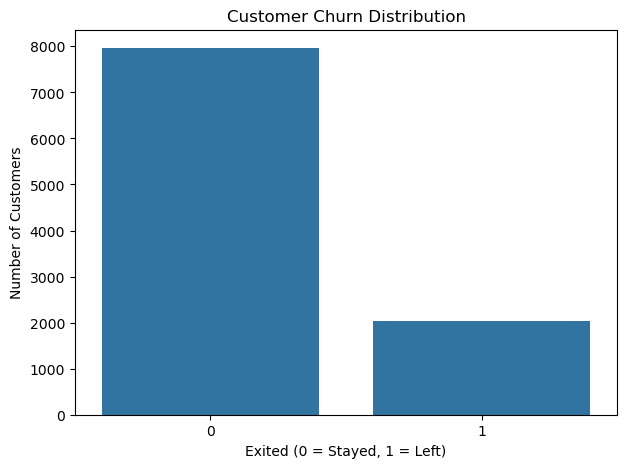

In [13]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x='Exited')

plt.title('Customer Churn Distribution')
plt.xlabel('Exited (0 = Stayed, 1 = Left)')
plt.ylabel('Number of Customers')

plt.show()

## Target Variable Analysis


### Class Distribution

| Customer Status | Count | Percentage |
|---|---:|---:|
| Stayed (0) | 7,963 | 79.63% |
| Exited (1) | 2,037 | 20.37% |
| Total | 10,000 | 100% |

### Key Findings

1. Most customers (79.63%) stayed with the bank.
2. Only 20.37% of customers left the bank.
3. The target variable shows class imbalance.

### Business Insight

Customer churn prediction is important because identifying
customers who may leave can help the bank take preventive
actions and improve customer retention.



In [14]:
df['Geography'].value_counts()

Geography
France     5014
Germany    2509
Spain      2477
Name: count, dtype: int64

In [15]:
df['Gender'].value_counts()

Gender
Male      5457
Female    4543
Name: count, dtype: int64

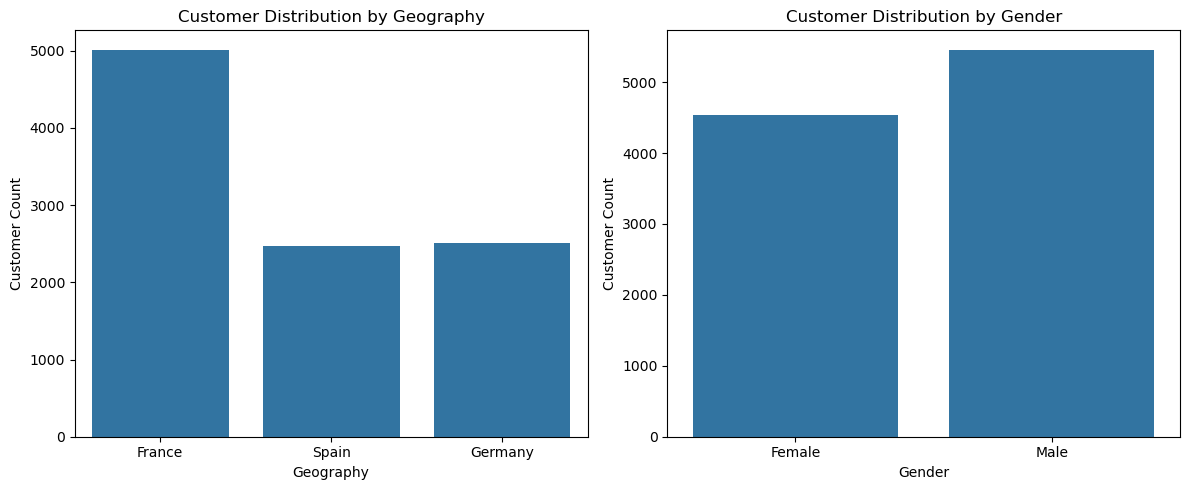

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.countplot(data=df, x='Geography', ax=axes[0])
axes[0].set_title('Customer Distribution by Geography')
axes[0].set_xlabel('Geography')
axes[0].set_ylabel('Customer Count')

sns.countplot(data=df, x='Gender', ax=axes[1])
axes[1].set_title('Customer Distribution by Gender')
axes[1].set_xlabel('Gender')
axes[1].set_ylabel('Customer Count')

plt.tight_layout()
plt.show()

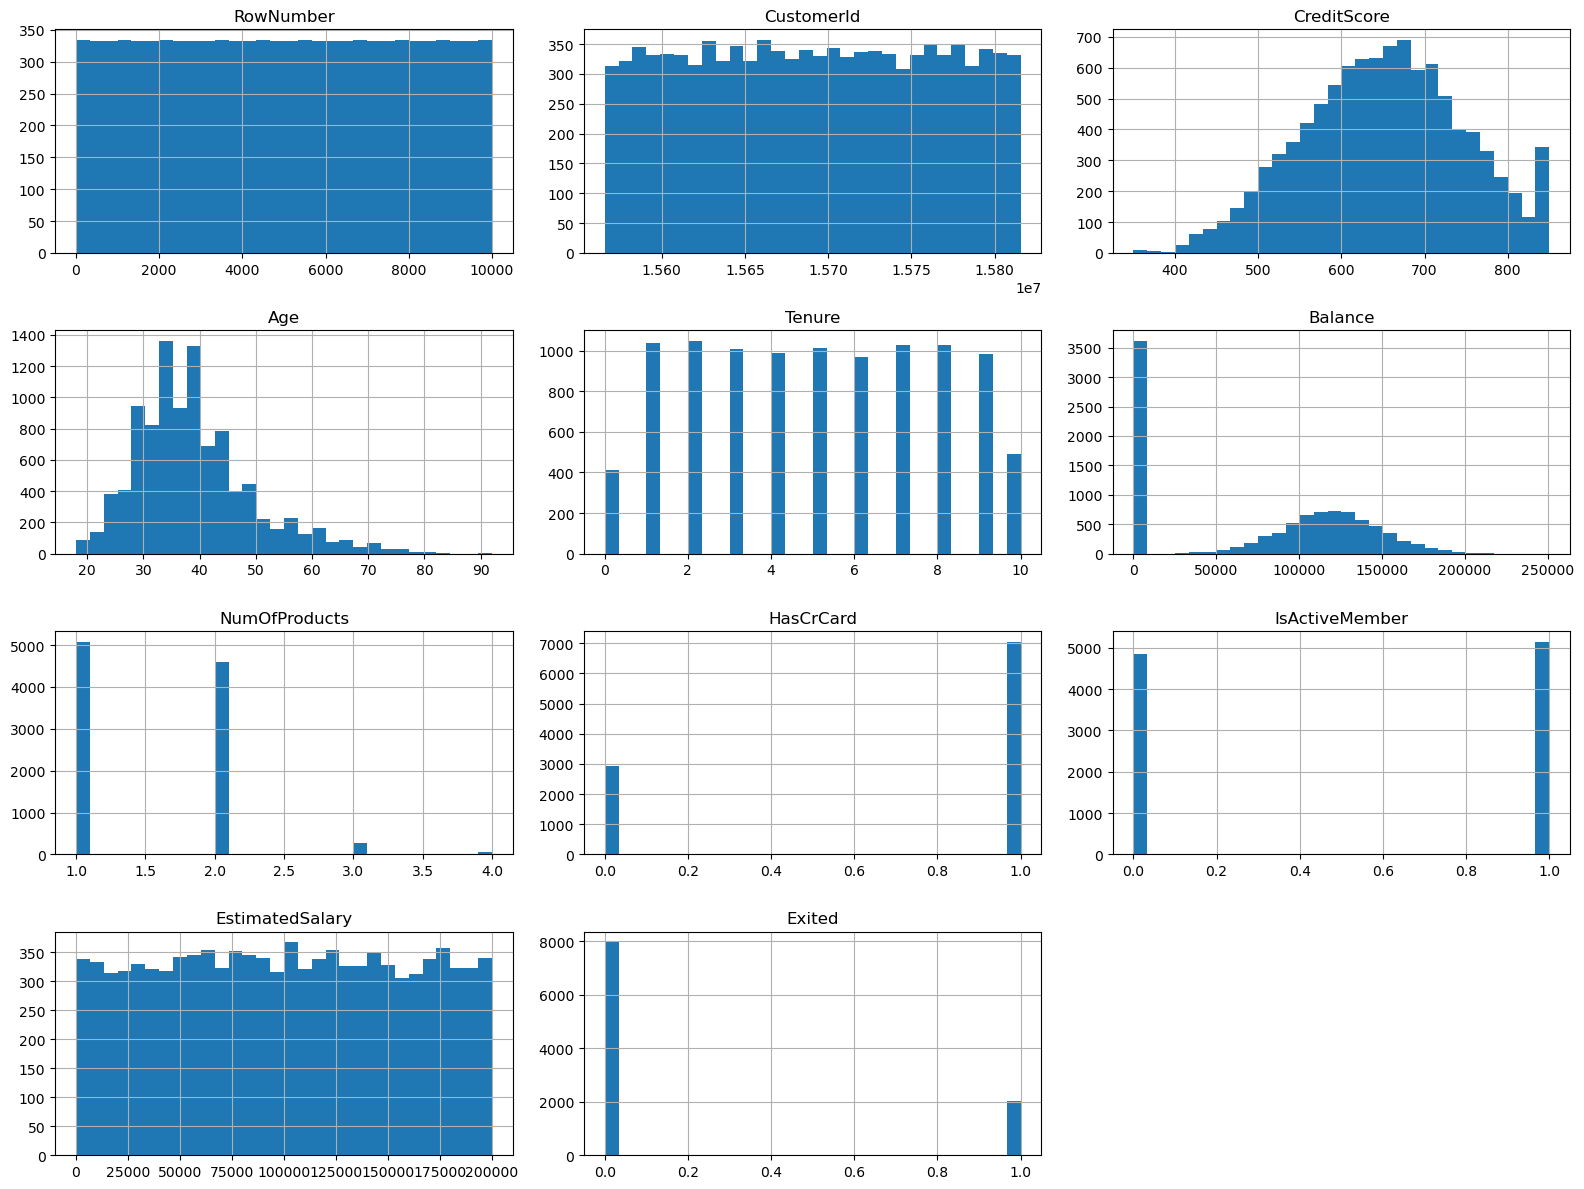

In [17]:
df.select_dtypes(include=['int64', 'float64']).hist(
    figsize=(16, 12),
    bins=30
)

plt.tight_layout()
plt.show()

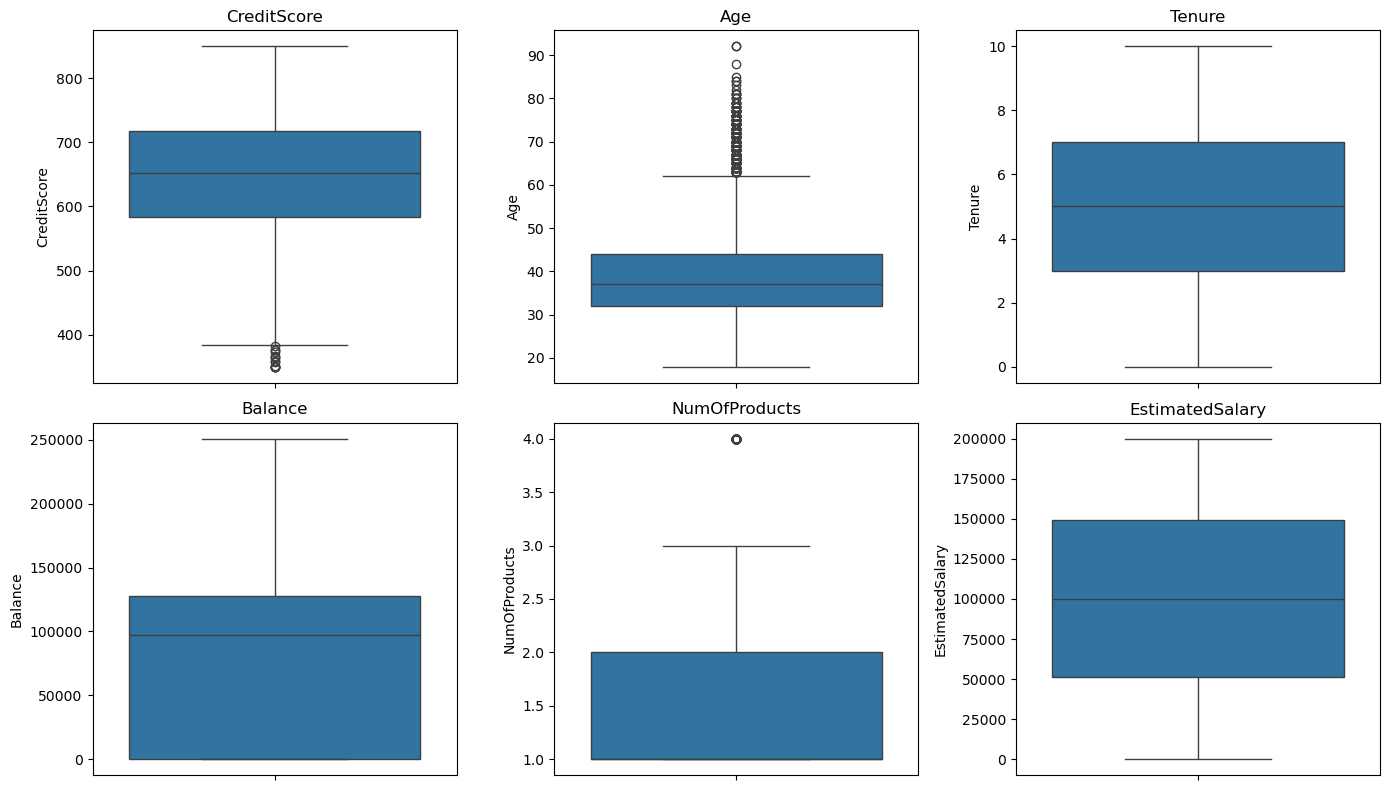

In [18]:
numerical_cols = [
    'CreditScore',
    'Age',
    'Tenure',
    'Balance',
    'NumOfProducts',
    'EstimatedSalary'
]

plt.figure(figsize=(14, 8))

for i, col in enumerate(numerical_cols, 1):
    plt.subplot(2, 3, i)
    sns.boxplot(y=df[col])
    plt.title(col)

plt.tight_layout()
plt.show()

In [19]:
numerical_cols = [
    'CreditScore',
    'Age',
    'Tenure',
    'Balance',
    'EstimatedSalary'
]

for col in numerical_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df[(df[col] < lower) | (df[col] > upper)]

    print(f"{col}: {len(outliers)} potential outliers")

CreditScore: 15 potential outliers
Age: 359 potential outliers
Tenure: 0 potential outliers
Balance: 0 potential outliers
EstimatedSalary: 0 potential outliers


## [Q1-1.5(IQR), Q3+1.5(IQR)]

### Inspect Age outliers

In [20]:
Q1 = df['Age'].quantile(0.25)
Q3 = df['Age'].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

df[df['Age'] > upper]['Age'].sort_values().head(20)

1235    63
1285    63
567     63
9162    63
8562    63
8602    63
2053    63
9351    63
2459    63
2615    63
9438    63
8761    63
2078    63
3314    63
2926    63
8207    63
3346    63
7727    63
7776    63
6812    63
Name: Age, dtype: int64

This is important: 63 is not automatically an invalid age. It may simply be a valid customer age that falls outside the IQR range.

In [21]:
df['Age'].describe()

count    10000.000000
mean        38.921800
std         10.487806
min         18.000000
25%         32.000000
50%         37.000000
75%         44.000000
max         92.000000
Name: Age, dtype: float64

What does this tell us?
1. The customer ages range from 18 to 92.
2. Most customers are relatively young or middle-aged.
3. The IQR method flagged some ages above its upper boundary.
4. However, older customers can be genuine bank customers. These values are not necessarily errors.
- Decision: Keep the Age column unchanged.

### Inspect CreditScore outliers

In [22]:
Q1 = df['CreditScore'].quantile(0.25)
Q3 = df['CreditScore'].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

df[
    (df['CreditScore'] < lower) |
    (df['CreditScore'] > upper)
]['CreditScore'].sort_values()

1838    350
1631    350
8723    350
8762    350
9624    350
2473    351
1962    358
1405    359
1193    363
2579    365
8154    367
9356    373
942     376
7       376
9210    382
Name: CreditScore, dtype: int64

In [23]:
df['CreditScore'].describe()

count    10000.000000
mean       650.528800
std         96.653299
min        350.000000
25%        584.000000
50%        652.000000
75%        718.000000
max        850.000000
Name: CreditScore, dtype: float64

Interpretation
- These values are relatively low compared with the general customer credit scores.
- However, a low credit score does not necessarily mean the data is incorrect.
- These could be genuine customers with lower creditworthiness.
- We should not delete these records just because the IQR method identifies them as outliers.

In [24]:
print("Geography:", df['Geography'].unique())

print("Gender:", df['Gender'].unique())

Geography: ['France' 'Spain' 'Germany']
Gender: ['Female' 'Male']


In [25]:
print("HasCrCard:")
print(df['HasCrCard'].value_counts())

print("\nIsActiveMember:")
print(df['IsActiveMember'].value_counts())

HasCrCard:
HasCrCard
1    7055
0    2945
Name: count, dtype: int64

IsActiveMember:
IsActiveMember
1    5151
0    4849
Name: count, dtype: int64


In [26]:
df['NumOfProducts'].value_counts().sort_index()

NumOfProducts
1    5084
2    4590
3     266
4      60
Name: count, dtype: int64

In [27]:
df['Tenure'].value_counts().sort_index()

Tenure
0      413
1     1035
2     1048
3     1009
4      989
5     1012
6      967
7     1028
8     1025
9      984
10     490
Name: count, dtype: int64

Important observations
1. The minimum tenure is 0 years.
2. The maximum tenure is 10 years.
3. Most customers have been associated with the bank for 1–9 years.
4. No unexpected tenure values were found.

In [28]:
df['Balance'].describe()

count     10000.000000
mean      76485.889288
std       62397.405202
min           0.000000
25%           0.000000
50%       97198.540000
75%      127644.240000
max      250898.090000
Name: Balance, dtype: float64

In [29]:
(df['Balance'] == 0).sum()

np.int64(3617)

Zero balance is a valid financial condition, not a missing value. It may also be useful for predicting customer churn.

In [30]:
df['EstimatedSalary'].describe()

count     10000.000000
mean     100090.239881
std       57510.492818
min          11.580000
25%       51002.110000
50%      100193.915000
75%      149388.247500
max      199992.480000
Name: EstimatedSalary, dtype: float64

In [32]:
print("Unique RowNumber:", df['RowNumber'].nunique())
print("Unique CustomerId:", df['CustomerId'].nunique())
print("Unique Surname:", df['Surname'].nunique())

Unique RowNumber: 10000
Unique CustomerId: 10000
Unique Surname: 2932


1. RowNumber — Remove
- It is only a serial number.
- It does not describe customer behaviour.
- It has no meaningful predictive information.
2. CustomerId — Remove
- It uniquely identifies each customer.
- It is an identifier, not a meaningful financial feature.
- Using it could encourage the model to learn meaningless patterns.
3. Surname — Remove
- It contains customers' last names.
- It has 2,932 unique categories.
- It is unlikely to provide useful generalizable information for this prediction task.

In [33]:
df.drop(
    columns=['RowNumber', 'CustomerId', 'Surname'],
    inplace=True
)

In [34]:
df.shape

(10000, 11)

In [35]:
df.columns

Index(['CreditScore', 'Geography', 'Gender', 'Age', 'Tenure', 'Balance',
       'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary',
       'Exited'],
      dtype='object')

In [36]:
df.to_csv("churn_cleaned.csv", index=False)

In [37]:
# index=False prevents Pandas from adding an unnecessary index column.


# Customer Churn Prediction
## Data Understanding and Cleaning: Complete Revision

Observation:
The dataset has moderate class imbalance because the number of customers who stayed is significantly higher than the number who exited.

Therefore, model evaluation should consider Precision, Recall, F1-score and ROC-AUC, not just Accuracy.

###  Categorical Feature Analysis

**Geography**
- France: 5,014
- Germany: 2,509
- Spain: 2,477

**Gender**
- Male: 5,457
- Female: 4,543

No unexpected categorical values were identified.

###  Numerical Feature and Outlier Analysis

Used:
- `df.describe()`
- Histograms
- Boxplots
- Interquartile Range (IQR) method

IQR formula:

IQR = Q3 - Q1

Lower Bound = Q1 - 1.5 × IQR

Upper Bound = Q3 + 1.5 × IQR

Potential outliers:

| Feature | Potential Outliers |
|---|---:|
| CreditScore | 15 |
| Age | 359 |
| Tenure | 0 |
| Balance | 0 |
| EstimatedSalary | 0 |

Important observations:
- Age values ranged from 18 to 92.
- CreditScore values ranged from 350 to 850.
- Potential outliers were investigated.
- No confirmed invalid values were identified.
- Potential outliers were retained because unusual values are not automatically incorrect.

### Additional Feature Analysis

**HasCrCard**
- 1: 7,055 customers
- 0: 2,945 customers

**IsActiveMember**
- 1: 5,151 customers
- 0: 4,849 customers

**NumOfProducts**
- 1 product: 5,084 customers
- 2 products: 4,590 customers
- 3 products: 266 customers
- 4 products: 60 customers

**Tenure**
- Values ranged from 0 to 10 years.
- No unexpected values were found.

**Balance**
- 3,617 customers had a zero balance.
- Zero is a valid numerical value, not automatically a missing value.
- Zero balances were retained.

**EstimatedSalary**
- Mean: 100,090.24
- Minimum: 11.58
- Maximum: 199,992.48

###  Removing Unnecessary Columns

Removed the following columns:

| Column | Reason |
|---|---|
| RowNumber | Only represents row sequence |
| CustomerId | Unique customer identifier |
| Surname | Customer name with high cardinality and limited predictive usefulness |


| Description | Result |
|---|---:|
| Total rows | 10,000 |
| Original columns | 14 |
| Removed columns | 3 |
| Remaining columns | 11 |
| Missing values | 0 |
| Duplicate rows | 0 |

Saved the cleaned dataset as:

`churn_cleaned.csv`

### Final Conclusion

The original dataset contained 10,000 records and 14 columns.

After completing data understanding and cleaning:
- Three unnecessary identification columns were removed.
- No missing values or duplicate rows were found.
- Potential outliers were investigated and retained.
- Valid zero balances and less frequent categories were preserved.
- The cleaned dataset contains 10,000 records and 11 columns.

The cleaned dataset is now ready for further Exploratory Data Analysis (EDA), where we will investigate relationships between customer features and churn behaviour.

**Next Stage: Exploratory Data Analysis (EDA).**
